# 09 — Contact Volume Forecasting

## 1. Introduction and objectives

CallVerse must know **how many contacts to expect** in order to plan staff (DSO3) and prepare for busy periods (DSO4). This notebook (Phase 2) forecasts the daily number of synthetic contacts and compares five models with an honest backtest.

**Forecasting task**

| Item | Choice |
|---|---|
| Target | Daily contacts for the 4 **intent groups** (`wismo`, `post_delivery`, `order_admin`, `cancel_refund`). The total is the **sum** of the group forecasts, so the levels always add up. |
| Planning rhythm | Every **Sunday** (the forecast origin), forecast **Monday to Sunday** of the next week: horizons 1 to 7 days. |
| Evaluation | **Rolling-origin backtest**: at each weekly origin, every model is re-trained on data up to that Sunday only, then forecasts the next 7 days. |
| Test period | Origins from 1 October 2017 to 12 August 2018. This covers the December 2017 wave of contacts after Black Friday. |
| Last day used | **19 August 2018**: Olist purchases collapse after 21 August (notebook 04) and the final weeks are incomplete (notebook 08). |

**Models**

1. `seasonal_naive`: the value on the same weekday last week.
2. `weekday_mean_4w`: the average of the last 4 same weekdays.
3. `sarima`: SARIMA(1,1,1)(0,1,1)₇, a classic statistical model with a weekly pattern.
4. `prophet`: weekly pattern plus calendar events (holidays and promotion windows).
5. `lightgbm`: gradient-boosted trees using lags, the calendar and delivery drivers, with a **Poisson** objective suited to counts.

**Rules that keep the evaluation honest**

- **No leakage.** Every feature uses information from at least 7 days before the target day, which is always known at the origin for horizons up to 7. Calendar features are known in advance.
- **No tuning on the test period.** Model settings are fixed before the backtest.
- **Zero-safe metrics.** MAPE divides by each day's actual value and breaks on zero days, so we use **wMAPE** (total absolute error ÷ total actual), MAE, RMSE and bias.

> The contacts are **synthetic** (notebook 08). Forecast accuracy here measures how well models recover the patterns built into the generator from real Olist order dynamics. It is not the accuracy of a real contact center.

## 2. Imports, paths and settings

In [1]:
%matplotlib inline
from pathlib import Path
import logging
import warnings

import cmdstanpy
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Prophet's backend (cmdstanpy) logs two lines per fit; silence it (fit errors still raise exceptions)
cmdstanpy.disable_logging()
logging.getLogger("prophet").setLevel(logging.WARNING)
# On Windows, joblib cannot count physical CPU cores and prints a harmless traceback the first
# time it tries. The result is cached, so we trigger that first attempt here, silently.
import contextlib
import io
from joblib import cpu_count
with contextlib.redirect_stderr(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cpu_count(only_physical_cores=True)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "forecasts"

required_files = [
    PROCESSED_DIR / "synthetic_contacts_daily_by_group.parquet",
    PROCESSED_DIR / "olist_daily_activity.parquet",
    PROCESSED_DIR / "olist_orders_analytical.parquet",
    PROCESSED_DIR / "daily_calendar.parquet",
    PROCESSED_DIR / "promo_calendar_events.csv",
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing inputs: {missing_files}. Run notebooks 03 to 08 first.")
if not ARTIFACTS_DIR.exists():
    raise FileNotFoundError(f"Expected {ARTIFACTS_DIR} (part of the project structure).")

SERIES_START = pd.Timestamp("2017-01-01")
EVAL_END = pd.Timestamp("2018-08-19")      # last day used (a Sunday)
FIRST_ORIGIN = pd.Timestamp("2017-10-01")  # first forecast origin (a Sunday)
HORIZON = 7
MIN_FEATURE_LAG = 7                        # every lag-based feature is at least this old
TRAIN_START = pd.Timestamp("2017-02-05")   # first day with all lag features available
SEED = 42

origins = pd.date_range(FIRST_ORIGIN, EVAL_END - pd.Timedelta(days=HORIZON), freq="W-SUN")
if FIRST_ORIGIN.day_name() != "Sunday" or EVAL_END.day_name() != "Sunday":
    raise ValueError("Origins and the last day must be Sundays.")
print("Forecast origins:", len(origins), "from", origins[0].date(), "to", origins[-1].date())

Forecast origins: 46 from 2017-10-01 to 2018-08-12


## 3. Load the series

The daily contact counts per intent group come from notebook 08. Days without contacts are already present as zeros.

In [2]:
daily_group = pd.read_parquet(PROCESSED_DIR / "synthetic_contacts_daily_by_group.parquet")
series = daily_group.pivot(index="date", columns="intent_group", values="contacts").sort_index()
series = series.loc[SERIES_START:EVAL_END]
GROUPS = list(series.columns)

if series.isna().any().any():
    raise ValueError("The series must have no missing days.")
if len(series) != (EVAL_END - SERIES_START).days + 1:
    raise ValueError("The series must contain every day.")

print("Days:", len(series), "| groups:", GROUPS)
summary = series.describe().T[["mean", "std", "min", "max"]].round(2)
summary["zero_day_percent"] = ((series == 0).mean() * 100).round(1)
display(summary)

Days: 596 | groups: ['cancel_refund', 'order_admin', 'post_delivery', 'wismo']


,mean,std,min,max,zero_day_percent
intent_group,,,,,
cancel_refund,0.96,1.12,0.0,6.0,43.8
order_admin,1.80,1.51,0.0,8.0,21.0
post_delivery,4.42,3.60,0.0,19.0,11.6
wismo,7.78,6.95,0.0,44.0,6.0


## 4. Features for LightGBM

The statistical models (SARIMA, Prophet) and the naive baselines only use each group's own history. LightGBM uses a **feature table** with one row per (day, group). For a target day *t*:

| Feature family | Features | Why it is known at the origin |
|---|---|---|
| Own history | values 7, 14, 21 and 28 days earlier; their mean; mean of days *t*−13…*t*−7 and *t*−34…*t*−7 | at least 7 days old |
| Order drivers | 7-day means of purchases, carrier handoffs, deliveries and late deliveries, ending at *t*−7 | at least 7 days old |
| Promised dates | orders **promised** for day *t* (and for the 3 days before) that were placed at least 7 days earlier | the promised date is set at purchase |
| Overdue backlog | orders whose promised date passed in the 30 days before *t*−7 and that were not delivered by *t*−7 | counted at *t*−7 using only events up to *t*−7, including orders later canceled, because cancellation is not known in advance |
| Calendar | weekday, weekend, public holiday, promotion window and group, days to the next event, days since the last major sale | public calendar, known in advance |
| Group | which intent group | identity |

In [3]:
daily_activity = pd.read_parquet(PROCESSED_DIR / "olist_daily_activity.parquet").set_index("date")
orders = pd.read_parquet(PROCESSED_DIR / "olist_orders_analytical.parquet")
daily_calendar = pd.read_parquet(PROCESSED_DIR / "daily_calendar.parquet").set_index("date")
events = pd.read_csv(PROCESSED_DIR / "promo_calendar_events.csv", parse_dates=["event_day", "window_start", "window_end"])

all_days = daily_activity.index  # full Olist date range, so lags exist before 2017
date_features = pd.DataFrame(index=all_days)

# Order drivers: 7-day means ending 7 days before the target day
for column in ["orders_purchased", "orders_handed_to_carrier", "orders_delivered", "late_deliveries"]:
    date_features[f"{column}_mean7_lag7"] = daily_activity[column].shift(MIN_FEATURE_LAG).rolling(7).mean()

# Promised dates: orders promised for day t, placed at least 7 days before t
lead_days = (orders["order_estimated_delivery_date"] - orders["purchase_date"]).dt.days
promised_early = orders[lead_days >= MIN_FEATURE_LAG]
promised_per_day = promised_early.groupby("order_estimated_delivery_date").size()
date_features["promised_for_day"] = promised_per_day.reindex(all_days, fill_value=0)
# Days t-3..t-1, each also placed at least 7 days before its own date (stricter than needed)
date_features["promised_prev3_days"] = date_features["promised_for_day"].shift(1).rolling(3).sum()

# Overdue backlog at t-7: promised in the 30 days before, not delivered (yet) at that date
estimate = orders["order_estimated_delivery_date"].to_numpy()
delivered_at = orders["order_delivered_customer_date"].fillna(pd.Timestamp.max).to_numpy()
purchased_at = orders["order_purchase_timestamp"].to_numpy()
backlog = []
for day in all_days:
    day_value = np.datetime64(day)
    recently_due = (estimate < day_value) & (estimate >= day_value - np.timedelta64(30, "D"))
    not_delivered = delivered_at > day_value
    already_bought = purchased_at <= day_value
    backlog.append(int((recently_due & not_delivered & already_bought).sum()))
date_features["overdue_backlog_lag7"] = pd.Series(backlog, index=all_days).shift(MIN_FEATURE_LAG)

# Calendar of the target day (known in advance)
date_features["day_of_week"] = all_days.dayofweek
date_features["is_weekend"] = (all_days.dayofweek >= 5).astype(int)
date_features["is_public_holiday"] = daily_calendar["is_public_holiday"].reindex(all_days).astype(int)
date_features["in_promo_window"] = daily_calendar["in_promo_window"].reindex(all_days).astype(int)
promo_group_codes = {"major_sale": 1, "gift_season": 2}
date_features["promo_group_code"] = daily_calendar["promo_group"].reindex(all_days).map(promo_group_codes).fillna(0).astype(int)
date_features["days_to_next_event"] = daily_calendar["days_to_next_event_day"].reindex(all_days).astype("float").fillna(60).clip(upper=60)

major_sale_days = events.loc[events["event_group"] == "major_sale", "event_day"].sort_values().to_numpy()
days_since_major = []
for day in all_days:
    past_days = major_sale_days[major_sale_days <= np.datetime64(day)]
    days_since_major.append((day - pd.Timestamp(past_days[-1])).days if len(past_days) else 90)
date_features["days_since_major_sale"] = np.clip(days_since_major, None, 90)

display(date_features.loc["2017-11-20":"2017-12-03"].round(1))

,orders_purchased_mean7_lag7,orders_handed_to_carrier_mean7_lag7,orders_delivered_mean7_lag7,late_deliveries_mean7_lag7,promised_for_day,promised_prev3_days,overdue_backlog_lag7,day_of_week,is_weekend,is_public_holiday,in_promo_window,promo_group_code,days_to_next_event,days_since_major_sale
date,,,,,,,,,,,,,,
2017-11-20,175.6,137.3,137.7,6.3,0,265.0,230.0,0,0,0,0,0,4.0,90
2017-11-21,180.1,147.3,135.1,6.1,167,0.0,234.0,1,0,0,0,0,3.0,90
2017-11-22,181.7,117.7,114.0,6.0,195,167.0,247.0,2,0,0,0,0,2.0,90
2017-11-23,186.7,145.4,120.3,5.9,218,362.0,240.0,3,0,0,0,0,1.0,90
2017-11-24,191.3,162.7,121.1,5.9,213,580.0,246.0,4,0,0,1,1,0.0,0
2017-11-25,189.9,162.4,124.1,6.3,0,626.0,245.0,5,1,0,1,1,30.0,1
2017-11-26,187.6,162.4,124.6,6.3,0,431.0,234.0,6,1,0,1,1,29.0,2
2017-11-27,191.1,174.3,115.1,6.6,289,213.0,231.0,0,0,0,1,1,28.0,3
2017-11-28,196.3,179.0,123.6,6.4,214,289.0,221.0,1,0,0,0,0,27.0,4


In [4]:
# Own-history features per group (long table: one row per day and group)
panel_parts = []
for group_index, group in enumerate(GROUPS):
    values = series[group]
    part = pd.DataFrame({"date": series.index, "intent_group": group, "group_code": group_index, "contacts": values.to_numpy()})
    for lag in [7, 14, 21, 28]:
        part[f"lag_{lag}"] = values.shift(lag).to_numpy()
    part["same_weekday_mean_4"] = part[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)
    part["mean7_lag7"] = values.shift(MIN_FEATURE_LAG).rolling(7).mean().to_numpy()
    part["mean28_lag7"] = values.shift(MIN_FEATURE_LAG).rolling(28).mean().to_numpy()
    panel_parts.append(part)

panel = pd.concat(panel_parts, ignore_index=True)
panel = panel.merge(date_features, left_on="date", right_index=True, how="left", validate="many_to_one")

FEATURES = [column for column in panel.columns if column not in ["date", "intent_group", "contacts"]]
print("Feature table:", panel.shape, "| features:", len(FEATURES))
print(FEATURES)

# Leakage guard: each lag feature must equal the value exactly `lag` days before
check_rows = panel[(panel["intent_group"] == GROUPS[0]) & (panel["date"] == pd.Timestamp("2018-03-15"))]
expected_lag7 = series.loc[pd.Timestamp("2018-03-08"), GROUPS[0]]
print("Leakage guard (lag_7 on 2018-03-15 equals the value of 2018-03-08):",
      float(check_rows["lag_7"].iloc[0]) == float(expected_lag7))
train_like = panel[panel["date"] >= TRAIN_START]
print("Missing feature values from", TRAIN_START.date(), "onwards:", int(train_like[FEATURES].isna().sum().sum()))

Feature table: (2384, 25) | features: 22
['group_code', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'same_weekday_mean_4', 'mean7_lag7', 'mean28_lag7', 'orders_purchased_mean7_lag7', 'orders_handed_to_carrier_mean7_lag7', 'orders_delivered_mean7_lag7', 'late_deliveries_mean7_lag7', 'promised_for_day', 'promised_prev3_days', 'overdue_backlog_lag7', 'day_of_week', 'is_weekend', 'is_public_holiday', 'in_promo_window', 'promo_group_code', 'days_to_next_event', 'days_since_major_sale']
Leakage guard (lag_7 on 2018-03-15 equals the value of 2018-03-08): True
Missing feature values from 2017-02-05 onwards: 0


## 5. The models

Each function receives a forecast origin and returns the forecasts for the 7 following days, using only data up to the origin. All forecasts are clipped at 0, because a negative contact count is meaningless.

In [5]:
target_days_by_origin = {origin: pd.date_range(origin + pd.Timedelta(days=1), periods=HORIZON) for origin in origins}

def forecast_seasonal_naive(origin, group):
    target_days = target_days_by_origin[origin]
    return series.loc[target_days - pd.Timedelta(days=7), group].to_numpy()

def forecast_weekday_mean_4w(origin, group):
    target_days = target_days_by_origin[origin]
    past = [series.loc[target_days - pd.Timedelta(days=7 * k), group].to_numpy() for k in range(1, 5)]
    return np.mean(past, axis=0)

sarima_problems = {"not_converged": 0, "failed": 0}

def forecast_sarima(origin, group):
    history = series.loc[:origin, group].astype(float)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            model = SARIMAX(history.to_numpy(), order=(1, 1, 1), seasonal_order=(0, 1, 1, 7),
                            enforce_stationarity=False, enforce_invertibility=False)
            fitted = model.fit(disp=False, maxiter=200)
            forecast = fitted.forecast(HORIZON)
        except Exception:
            sarima_problems["failed"] += 1
            return forecast_seasonal_naive(origin, group)  # documented fallback
    if any("converge" in str(warning.message).lower() for warning in caught):
        sarima_problems["not_converged"] += 1
    return np.clip(forecast, 0, None)

calendar_holidays = []
for day, row in daily_calendar.iterrows():
    if row["is_public_holiday"]:
        calendar_holidays.append({"ds": day, "holiday": "public_holiday"})
    if row["in_promo_window"]:
        calendar_holidays.append({"ds": day, "holiday": str(row["promo_group"])})
prophet_holidays = pd.DataFrame(calendar_holidays)

def forecast_prophet(origin, group):
    history = pd.DataFrame({"ds": series.loc[:origin].index, "y": series.loc[:origin, group].to_numpy()})
    model = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                    holidays=prophet_holidays)
    model.fit(history)
    future = pd.DataFrame({"ds": target_days_by_origin[origin]})
    return np.clip(model.predict(future)["yhat"].to_numpy(), 0, None)

LIGHTGBM_PARAMS = {
    "objective": "poisson", "learning_rate": 0.05, "n_estimators": 400, "num_leaves": 15,
    "min_child_samples": 20, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8,
    "random_state": SEED, "deterministic": True, "force_row_wise": True, "verbose": -1,
}

def forecast_lightgbm(origin):
    # One global model for all groups (more training data than one model per group)
    train = panel[(panel["date"] >= TRAIN_START) & (panel["date"] <= origin)]
    test = panel[panel["date"].isin(target_days_by_origin[origin])]
    model = lgb.LGBMRegressor(**LIGHTGBM_PARAMS)
    model.fit(train[FEATURES], train["contacts"], categorical_feature=["group_code"])
    result = test[["date", "intent_group"]].copy()
    result["forecast"] = np.clip(model.predict(test[FEATURES]), 0, None)
    return result

**Fallback rule.** If SARIMA fails to fit at an origin, it falls back to `seasonal_naive` for that week, and the failure is counted. Non-converged fits are also counted and reported, not hidden.

## 6. Rolling-origin backtest

For each of the weekly origins, each model forecasts the next 7 days for each group. This takes a few minutes, because SARIMA and Prophet are re-fitted at every origin and for every group.

In [6]:
prediction_rows = []
for origin in origins:
    target_days = target_days_by_origin[origin]
    for group in GROUPS:
        group_forecasts = {
            "seasonal_naive": forecast_seasonal_naive(origin, group),
            "weekday_mean_4w": forecast_weekday_mean_4w(origin, group),
            "sarima": forecast_sarima(origin, group),
            "prophet": forecast_prophet(origin, group),
        }
        for model_name, values in group_forecasts.items():
            for horizon, (day, value) in enumerate(zip(target_days, values), start=1):
                prediction_rows.append({"origin": origin, "date": day, "horizon": horizon, "intent_group": group,
                                        "model": model_name, "forecast": float(value)})
    lightgbm_result = forecast_lightgbm(origin)
    for row in lightgbm_result.itertuples():
        prediction_rows.append({"origin": origin, "date": row.date, "horizon": (row.date - origin).days,
                                "intent_group": row.intent_group, "model": "lightgbm", "forecast": float(row.forecast)})

predictions = pd.DataFrame(prediction_rows)
actuals = series.stack().rename("actual").reset_index()
predictions = predictions.merge(actuals, on=["date", "intent_group"], how="left", validate="many_to_one")
print("Predictions:", len(predictions))
print("SARIMA problems:", sarima_problems)

Predictions: 6440
SARIMA problems: {'not_converged': 0, 'failed': 0}


In [7]:
MODELS = ["seasonal_naive", "weekday_mean_4w", "sarima", "prophet", "lightgbm"]
expected_rows = len(origins) * HORIZON * len(GROUPS) * len(MODELS)
backtest_checks = [
    ("One forecast per origin, day, group and model", len(predictions) == expected_rows
     and not predictions.duplicated(["origin", "date", "intent_group", "model"]).any()),
    ("No missing forecast or actual", not predictions[["forecast", "actual"]].isna().any().any()),
    ("No negative forecast", bool((predictions["forecast"] >= 0).all())),
    ("Every target day is after its origin and within 7 days", bool(predictions["horizon"].between(1, HORIZON).all())),
    ("No target day after the last day used", bool((predictions["date"] <= EVAL_END).all())),
]
display(pd.DataFrame(backtest_checks, columns=["check", "passed"]))

# Total = sum of the group forecasts (and of the group actuals)
total = predictions.groupby(["origin", "date", "horizon", "model"], as_index=False)[["forecast", "actual"]].sum()
total["intent_group"] = "total"
all_levels = pd.concat([predictions, total], ignore_index=True)

,check,passed
0,"One forecast per origin, day, group and model",True
1,No missing forecast or actual,True
2,No negative forecast,True
3,Every target day is after its origin and withi...,True
4,No target day after the last day used,True


## 7. Results

### 7.1 Accuracy per model and level

- **wMAPE** = Σ|actual − forecast| ÷ Σ actual: the share of volume that is wrong. Lower is better.
- **MAE**: average absolute error in contacts per day.
- **RMSE**: like MAE but punishes large misses more.
- **Bias** = Σ(forecast − actual) ÷ Σ actual: positive means over-forecasting.

In [8]:
def accuracy(table):
    error = table["forecast"] - table["actual"]
    return pd.Series({
        "wMAPE_percent": error.abs().sum() / table["actual"].sum() * 100,
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "bias_percent": error.sum() / table["actual"].sum() * 100,
    })

metrics = all_levels.groupby(["intent_group", "model"]).apply(accuracy, include_groups=False).round(2).reset_index()
level_order = ["total"] + sorted(GROUPS, key=lambda group: -series[group].sum())

wmape_table = metrics.pivot(index="intent_group", columns="model", values="wMAPE_percent").loc[level_order, MODELS]
print("wMAPE (%) - lower is better:")
display(wmape_table)
best_model = wmape_table.idxmin(axis=1).rename("best_model")
display(best_model.to_frame())
print("Total level, all metrics:")
display(metrics[metrics["intent_group"] == "total"].set_index("model").loc[MODELS])

wMAPE (%) - lower is better:


model,seasonal_naive,weekday_mean_4w,sarima,prophet,lightgbm
intent_group,,,,,
total,31.56,31.91,27.65,35.85,25.28
wismo,45.49,48.77,42.26,52.10,36.88
post_delivery,45.05,41.89,35.22,43.75,38.01
order_admin,68.03,55.92,53.67,52.68,54.69
cancel_refund,102.86,86.14,81.29,90.52,83.83


,best_model
intent_group,
total,lightgbm
wismo,lightgbm
post_delivery,sarima
order_admin,prophet
cancel_refund,sarima


Total level, all metrics:


,intent_group,wMAPE_percent,MAE,RMSE,bias_percent
model,,,,,
seasonal_naive,total,31.56,6.65,8.54,-1.70
weekday_mean_4w,total,31.91,6.72,8.63,-3.46
sarima,total,27.65,5.83,7.62,-0.24
prophet,total,35.85,7.55,9.72,5.39
lightgbm,total,25.28,5.33,6.99,-2.03


### 7.2 Accuracy by horizon (total level)

Forecasts further ahead are usually less accurate. This shows how much accuracy is lost from Monday (horizon 1) to Sunday (horizon 7).

In [9]:
total_level = all_levels[all_levels["intent_group"] == "total"]
by_horizon = total_level.groupby(["horizon", "model"]).apply(accuracy, include_groups=False)["wMAPE_percent"].unstack()[MODELS]
display(by_horizon.round(2))

model,seasonal_naive,weekday_mean_4w,sarima,prophet,lightgbm
horizon,,,,,
1,31.86,27.89,23.06,36.08,20.90
2,36.77,32.66,29.58,34.60,27.66
3,29.02,34.29,28.09,37.50,25.58
4,30.50,32.67,26.62,33.42,25.41
5,31.04,30.52,24.90,32.33,23.39
6,33.80,34.65,33.20,39.26,29.72
7,28.24,29.68,27.72,38.35,23.66


### 7.3 Weekly totals and special periods

Staff are planned per week, so we also measure the error on **weekly totals**. Errors on individual days partly cancel out inside a week. We then check two difficult periods:

- **December 2017**: the wave of contacts following the Black Friday orders.
- **Promotion-window days** in the test period.

In [10]:
weekly = total_level.groupby(["origin", "model"], as_index=False)[["forecast", "actual"]].sum()
weekly_accuracy = weekly.groupby("model").apply(accuracy, include_groups=False).loc[MODELS, ["wMAPE_percent", "bias_percent"]]
weekly_accuracy.columns = ["weekly_wMAPE_percent", "weekly_bias_percent"]

december = total_level[total_level["date"].between("2017-12-01", "2017-12-31")]
december_accuracy = december.groupby("model").apply(accuracy, include_groups=False).loc[MODELS, ["wMAPE_percent", "bias_percent"]]
december_accuracy.columns = ["december_2017_wMAPE_percent", "december_2017_bias_percent"]

promo_days = daily_calendar.index[daily_calendar["in_promo_window"]]
promo = total_level[total_level["date"].isin(promo_days)]
promo_accuracy = promo.groupby("model").apply(accuracy, include_groups=False).loc[MODELS, ["wMAPE_percent"]]
promo_accuracy.columns = ["promo_days_wMAPE_percent"]

print("Promotion-window days in the test period:", promo["date"].nunique())
display(pd.concat([weekly_accuracy, december_accuracy, promo_accuracy], axis=1).round(2))

Promotion-window days in the test period: 58


,weekly_wMAPE_percent,weekly_bias_percent,december_2017_wMAPE_percent,december_2017_bias_percent,promo_days_wMAPE_percent
model,,,,,
seasonal_naive,19.97,-1.70,39.56,1.23,31.43
weekday_mean_4w,26.41,-3.46,40.39,-24.91,38.20
sarima,20.30,-0.24,39.32,3.14,26.75
prophet,30.70,5.39,36.50,-31.78,39.28
lightgbm,17.01,-2.03,35.04,1.60,27.72


### 7.4 Forecast versus actual (total contacts)

The chart compares actual daily contacts with the LightGBM forecasts over the test period. Each point is a forecast made on the previous Sunday.

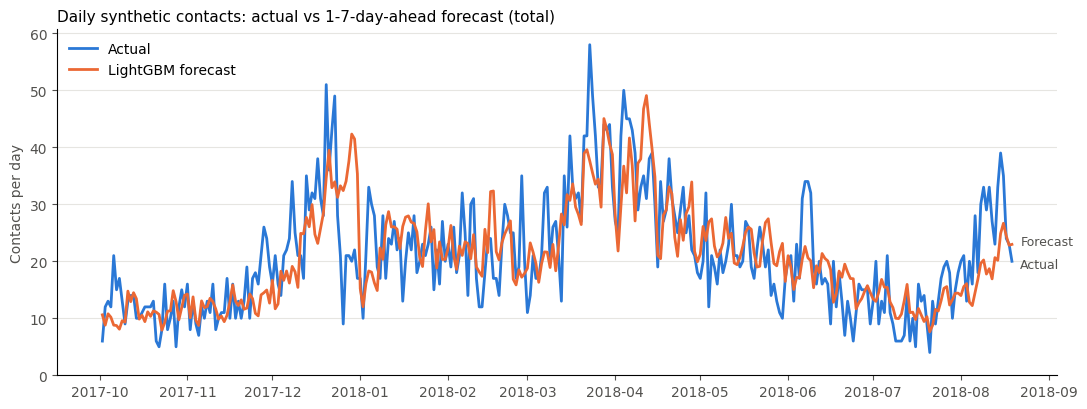

In [11]:
ACTUAL_COLOR = "#2a78d6"    # reference categorical slot 1 (validated palette)
FORECAST_COLOR = "#eb6834"  # reference categorical slot 2
TEXT_SECONDARY = "#52514e"

plot_data = total_level[total_level["model"] == "lightgbm"].sort_values("date")
figure, axis = plt.subplots(figsize=(11, 4.2))
axis.plot(plot_data["date"], plot_data["actual"], color=ACTUAL_COLOR, linewidth=2, label="Actual")
axis.plot(plot_data["date"], plot_data["forecast"], color=FORECAST_COLOR, linewidth=2, label="LightGBM forecast")

# Direct labels at the right end; pushed apart when the two lines end close together
last_point = plot_data.iloc[-1]
label_positions = {"Actual": float(last_point["actual"]), "Forecast": float(last_point["forecast"])}
MIN_LABEL_GAP = 4.0  # contacts
if abs(label_positions["Actual"] - label_positions["Forecast"]) < MIN_LABEL_GAP:
    middle = (label_positions["Actual"] + label_positions["Forecast"]) / 2
    upper_label = "Actual" if label_positions["Actual"] >= label_positions["Forecast"] else "Forecast"
    lower_label = "Forecast" if upper_label == "Actual" else "Actual"
    label_positions[upper_label] = middle + MIN_LABEL_GAP / 2
    label_positions[lower_label] = middle - MIN_LABEL_GAP / 2
for label, y_value in label_positions.items():
    axis.annotate(label, (last_point["date"], y_value), xytext=(6, 0), textcoords="offset points",
                  color=TEXT_SECONDARY, va="center", fontsize=9, annotation_clip=False)

axis.set_title("Daily synthetic contacts: actual vs 1-7-day-ahead forecast (total)", loc="left", fontsize=11)
axis.set_ylabel("Contacts per day", color=TEXT_SECONDARY)
axis.set_ylim(bottom=0)
axis.grid(axis="y", color="#e6e5e1", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.tick_params(colors=TEXT_SECONDARY)
axis.legend(frameon=False, loc="upper left")
figure.tight_layout()
figure.savefig(ARTIFACTS_DIR / "contact_forecast_backtest_total.png", dpi=150)
plt.show()

### 7.5 How good can a forecast be? The noise floor

The generator decides each contact with a random draw (notebook 08). Even a forecaster that knew the **true expected** number of contacts for every day could not predict the random part, so part of the error is **irreducible**.

For counts produced this way (approximately Poisson), a perfect forecast of expected value λ still misses by about √(2λ/π) contacts per day on average. We estimate λ for each day with a centred 7-day moving average of the actual series, and compute the wMAPE such a perfect forecaster would get.

This is an **approximation** (the moving average is itself noisy, and it smooths real weekly patterns), but it shows how much of each model's error is unavoidable.

In [12]:
test_days = pd.DatetimeIndex(sorted(predictions["date"].unique()))
level_series = series.copy()
level_series["total"] = series.sum(axis=1)

floor_rows = []
for level in level_order:
    expected_level = level_series[level].rolling(7, center=True, min_periods=4).mean().loc[test_days]
    floor_wmape = np.sqrt(2 * expected_level / np.pi).sum() / expected_level.sum() * 100
    best = wmape_table.loc[level].min()
    floor_rows.append({"level": level, "mean_contacts_per_day": round(expected_level.mean(), 2),
                       "noise_floor_wMAPE_percent": round(floor_wmape, 1),
                       "best_model": wmape_table.loc[level].idxmin(), "best_model_wMAPE_percent": best,
                       "best_minus_floor_points": round(best - floor_wmape, 1)})
display(pd.DataFrame(floor_rows))

,level,mean_contacts_per_day,noise_floor_wMAPE_percent,best_model,best_model_wMAPE_percent,best_minus_floor_points
0,total,21.09,17.0,lightgbm,25.28,8.2
1,wismo,11.17,23.0,lightgbm,36.88,13.9
2,post_delivery,6.47,30.7,sarima,35.22,4.5
3,order_admin,2.36,51.1,prophet,52.68,1.6
4,cancel_refund,1.08,72.6,sarima,81.29,8.7


**Reading the noise floor.** The fewer contacts per day, the higher the unavoidable wMAPE. That is why `cancel_refund` (about one contact per day) looks so bad for every model: most of its error is pure randomness. The gap between the best model and the floor (`best_minus_floor_points`) is the part a better model could still win.

## 8. What LightGBM relies on

We train LightGBM once more on all data up to the last day and look at **feature importance (gain)**: how much each feature improved the model's fit. High importance does not prove a cause; it shows which signals the model uses.

In [13]:
final_train = panel[(panel["date"] >= TRAIN_START) & (panel["date"] <= EVAL_END)]
final_model = lgb.LGBMRegressor(**LIGHTGBM_PARAMS)
final_model.fit(final_train[FEATURES], final_train["contacts"], categorical_feature=["group_code"])

importance = pd.Series(final_model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
importance = (importance / importance.sum() * 100).sort_values(ascending=False).round(2).rename("gain_percent")
display(importance.to_frame())

,gain_percent
mean28_lag7,31.41
mean7_lag7,28.54
same_weekday_mean_4,9.27
lag_7,4.90
days_since_major_sale,4.33
promised_prev3_days,4.29
group_code,4.08
orders_purchased_mean7_lag7,2.14
overdue_backlog_lag7,1.87
late_deliveries_mean7_lag7,1.73


## 9. Export

Backtest predictions and metrics are saved in `artifacts/forecasts/`, the project's location for forecast outputs, together with the final LightGBM model.

In [14]:
predictions_path = ARTIFACTS_DIR / "contact_forecast_backtest_predictions.parquet"
metrics_path = ARTIFACTS_DIR / "contact_forecast_backtest_metrics.csv"
model_path = ARTIFACTS_DIR / "lightgbm_contact_forecast_v1.txt"

all_levels.to_parquet(predictions_path, index=False)
metrics.to_csv(metrics_path, index=False)
final_model.booster_.save_model(str(model_path))

print(predictions_path.name, "-", len(pd.read_parquet(predictions_path)), "rows")
print(metrics_path.name, "-", len(pd.read_csv(metrics_path)), "rows")
print(model_path.name, "-", round(model_path.stat().st_size / 1024, 1), "KB")

contact_forecast_backtest_predictions.parquet - 8050 rows
contact_forecast_backtest_metrics.csv - 25 rows
lightgbm_contact_forecast_v1.txt - 679.8 KB


## 10. Summary and limitations

**Reading the results**

- In this run, **LightGBM** has the lowest error on the **total** and on the largest group (`wismo`), with the smallest weekly error and almost no bias in December 2017. SARIMA is a strong second and wins on two smaller groups; Prophet is the weakest, and it under-forecasts the post-Black-Friday wave.
- Accuracy is much better on **weekly totals** than on single days, which is what staff planning needs.
- **Much of the remaining daily error is irreducible noise** (section 7.5), especially for small groups.
- **Sparse groups are harder.** `cancel_refund` has many zero days, so its wMAPE is high for every model; its absolute error (MAE) stays small. This is the imbalance identified in notebook 08, and the reason we forecast groups instead of single intents.
- **Recommendation for the twin:** use LightGBM for the total and for `wismo`. For small groups, SARIMA or a simple per-group model is as good; an ensemble is a possible improvement.

**Guarantees**

- No leakage: every feature is at least 7 days old or comes from the public calendar; a lag check confirms the alignment.
- No tuning on the test period; fixed seeds; deterministic LightGBM.
- Forecasts are non-negative, and group forecasts add up to the total.

**Limitations**

- **Synthetic target.** The contacts follow the notebook 06 assumptions. Models are scored on recovering those patterns, not real customer behaviour.
- **Short history.** About 20 months; only one Black Friday, so promotion effects rest on very few examples (notebook 07).
- **Fixed model settings.** No hyperparameter search was done, by design. A tuning step would need its own validation period *before* the test period.
- **Point forecasts only.** Staffing benefits from uncertainty ranges (for example, 80% intervals). That is a candidate improvement.
- **Interpret feature importance with care.** The generator builds contacts from order situations, so delivery drivers are expected to matter.

**Next step:** the forecasts feed the discrete-event simulation (SimPy) and the shift planning (OR-Tools) phases.